<a href="https://colab.research.google.com/github/abhimanu854/Capstone_project/blob/main/capstone_B_tdr_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Finding a hidden fault in a cable (TDR inversion)
**Capstone Problem B** · PDEs, Transforms & Optimization · S3 EC

**Idea in simple words:** a 1 m cable has a damaged spot near the middle. We send a voltage step in, record the voltage at the start, and use the *echo* to find the fault.

**How to use in Google Colab:** click *Runtime → Run all*. Everything runs in under a minute. The libraries used are NumPy, SciPy, Matplotlib and SymPy (Colab already has them).

| Cell | Stage | Course |
|---|---|---|
| 1 | Setup | - |
| 2 | Stage 3: Laplace transform (sympy) | Transforms |
| 3 | Stages 2 and 4: finite-difference model and the matrix A | PDE, Linear Algebra |
| 4 | Stage 5: linear program (`linprog`) | Optimization |
| 5-7 | Stage 6: run, plot, check | Python Lab |

## 1. Setup

In [ ]:
# Colab already has these; the line is harmless if they are installed.
%pip install -q numpy scipy matplotlib sympy mpmath
import numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
print('ready')

ready


## 2. Stage 3 - Laplace transform of the telegrapher equations
With zero starting values the equations become
$\hat V' = -(R+Ls)\hat I,\quad \hat I' = -(G+Cs)\hat V \;\Rightarrow\; \hat V'' = \gamma^2 \hat V$,

$\gamma(s)=\sqrt{(R+Ls)(G+Cs)},\qquad Z_0(s)=\sqrt{\dfrac{R+Ls}{G+Cs}}$

In [ ]:
import sympy as sp
x, s = sp.symbols('x s', positive=True)
R, L, G, C = sp.symbols('R L G C', positive=True)
V = sp.Function('V')
gamma = sp.sqrt((R + L*s) * (G + C*s))
Z0s   = sp.sqrt((R + L*s) / (G + C*s))
sol = sp.dsolve(sp.Eq(V(x).diff(x, 2), gamma**2 * V(x)), V(x))
print('gamma(s) =', gamma)
print('Z0(s)    =', Z0s)
print('ODE solution:', sol)
print('check (should be 0):', sp.simplify(sol.rhs.diff(x, 2) - gamma**2 * sol.rhs))
print('Z0 as s -> infinity:', sp.limit(Z0s, s, sp.oo), '  (= sqrt(L/C), about 50 ohm)')

gamma(s) = sqrt(C*s + G)*sqrt(L*s + R)
Z0(s)    = sqrt(L*s + R)/sqrt(C*s + G)
ODE solution: Eq(V(x), C1*exp(-x*sqrt(C*s + G)*sqrt(L*s + R)) + C2*exp(x*sqrt(C*s + G)*sqrt(L*s + R)))
check (should be 0): 0
Z0 as s -> infinity: sqrt(L)/sqrt(C)   (= sqrt(L/C), about 50 ohm)


## 3. Stages 2 and 4 - the computer model and the matrix A
The cable is cut into 50 points. Voltage lives on the points, current between them. One time step is a matrix multiplication: $u^{n+1} = M u^n + e_0 V_s$.

Column *j* of the matrix **A** says how the recorded voltage changes if point *j* changes. The cell below holds all functions (the same file as `tdr_lib.py` in the repo).

In [ ]:
"""Core library for Capstone Problem B: TDR inversion of a telegrapher line.

Stage map (see README / report):
  Stage 2/4  : build_step_matrix()  -> sparse FDM update  u^{n+1} = M u^n + e*Vs
  Stage 4    : jacobian()           -> dense matrix A (TDR samples x parameter perturbations)
  Stage 5    : solve_l1_lp()        -> epigraph LP solved with scipy.optimize.linprog (HiGHS)
"""
import numpy as np
import scipy.sparse as sp
from scipy.optimize import linprog

# ----------------------------------------------------------------- constants
ELL = 1.0            # line length [m]
NX = 50              # number of spatial nodes
DX = ELL / (NX - 1)  # spacing [m]
R0, L0, G0, C0 = 0.1, 250e-9, 0.0, 100e-12
Z0_NOM = np.sqrt(L0 / C0)           # 50 ohm
V0_NOM = 1.0 / np.sqrt(L0 * C0)     # 2e8 m/s
FAULT_NODES = (24, 25, 26)          # 3 nodes around x = 0.5 m (x = 0.490 ... 0.531 m)
FAULT_R_FACTOR, FAULT_C_FACTOR = 4.0, 0.6
COURANT = 0.70                      # dt = COURANT*dx/v0 ; CFL at fault = 0.70/sqrt(0.6) = 0.90 < 1
DT = COURANT * DX / V0_NOM          # coarse (inversion) time step [s]
NT = 160                            # number of TDR samples (about 11.4 ns > round trip 10.2 ns)
RISE = 0.4e-9                       # 0-100 % rise time of the launched step [s]
VS_AMPL = 1.0                       # source step amplitude [V]
RS = Z0_NOM                         # source resistance (matched)
RLOAD = Z0_NOM                      # load resistance (matched)


def true_profiles():
    R = np.full(NX, R0)
    C = np.full(NX, C0)
    for j in FAULT_NODES:
        R[j] *= FAULT_R_FACTOR
        C[j] *= FAULT_C_FACTOR
    return R, C


def source(t, rise=RISE, ampl=VS_AMPL):
    """Raised-cosine step: smooth, band-limited launch signal."""
    t = np.asarray(t, dtype=float)
    u = np.clip(t / rise, 0.0, 1.0)
    return ampl * 0.5 * (1.0 - np.cos(np.pi * u))


# ----------------------------------------------------------- Stage 2 + 4: FDM
def build_step_matrix(R, L, G, C, dx, dt, rs=RS, rl=RLOAD):
    """Sparse one-step matrix of the staggered (leapfrog, semi-implicit loss) scheme.

    State u^n = [V^n (N nodes) ; I^{n-1/2} (N-1 half nodes)].
        L dI/dt = -dV/dx - R I     (half nodes, trapezoidal in R)
        C dV/dt = -dI/dx - G V     (nodes, half cell at both ends, with source / load)
    Returns (M, e0) with  u^{n+1} = M u^n + e0 * Vs(t^{n+1/2}).
    """
    n = len(C)
    # half-node (current) parameters = average of neighbouring nodes
    Rh = 0.5 * (R[:-1] + R[1:])
    Lh = 0.5 * (L[:-1] + L[1:])
    P = (Lh / dt - 0.5 * Rh) / (Lh / dt + 0.5 * Rh)
    Q = 1.0 / (Lh / dt + 0.5 * Rh)
    # node weights: half cell at the two ends
    w = np.full(n, dx)
    w[0] = w[-1] = 0.5 * dx
    gend = np.zeros(n)
    gend[0], gend[-1] = 1.0 / rs, 1.0 / rl
    alpha = C * w / dt + G * w / 2 + gend / 2
    beta = C * w / dt - G * w / 2 - gend / 2
    # operators
    Grad = sp.diags([-np.ones(n - 1), np.ones(n - 1)], [0, 1], shape=(n - 1, n)) / dx   # (V_{h+1}-V_h)/dx
    Div = sp.diags([np.ones(n - 1), -np.ones(n - 1)], [0, -1], shape=(n, n - 1))        # I_h - I_{h-1}
    Ainv = sp.diags(1.0 / alpha)
    Pd, Qd = sp.diags(P), sp.diags(Q)
    M11 = Ainv @ sp.diags(beta) + Ainv @ Div @ Qd @ Grad
    M12 = -Ainv @ Div @ Pd
    M21 = -Qd @ Grad
    M22 = Pd
    M = sp.bmat([[M11, M12], [M21, M22]], format="csr")
    e0 = np.zeros(2 * n - 1)
    e0[0] = 1.0 / (alpha[0] * rs)
    return M, e0


def simulate(R, L, G, C, dx, dt, nsteps, rise=RISE, rs=RS, rl=RLOAD, probe=0):
    """March the FDM; return time axis and V at node `probe` (the TDR port)."""
    M, e0 = build_step_matrix(R, L, G, C, dx, dt, rs, rl)
    u = np.zeros(M.shape[0])
    vs_mid = source((np.arange(nsteps) + 0.5) * dt, rise)
    out = np.zeros(nsteps + 1)
    for k in range(nsteps):
        u = M @ u + e0 * vs_mid[k]
        out[k + 1] = u[probe]
    return np.arange(nsteps + 1) * dt, out


def cfl_report(C, L=L0, dx=DX, dt=DT):
    vmax = 1.0 / np.sqrt(L * np.min(C))
    return vmax * dt / dx


# ------------------------------------------------------ measurement synthesis
def measured_trace(R, C, noise_sigma=0.0, seed=0, refine=4):
    """Synthetic TDR data. Generated on a grid `refine` times finer than the
    inversion grid (avoids the 'inverse crime'); parameters are piecewise
    constant on the 50-node cells.  Returns (t, V_meas)."""
    nf = (NX - 1) * refine + 1
    xc = np.arange(NX) * DX
    xf = np.arange(nf) * DX / refine
    idx = np.clip(np.rint(xf / DX).astype(int), 0, NX - 1)   # nearest coarse node owns the cell
    Rf, Cf = R[idx], C[idx]
    Lf, Gf = np.full(nf, L0), np.full(nf, G0)
    t, v = simulate(Rf, Lf, Gf, Cf, DX / refine, DT / refine, NT * refine)
    t, v = t[::refine], v[::refine]
    rng = np.random.default_rng(seed)
    return t, v + noise_sigma * rng.standard_normal(v.shape)


# ------------------------------------------------------ model on the inversion grid
MODEL_REFINE = 4   # inversion model uses a grid MODEL_REFINE x finer than the 50 parameter cells


def model_trace(r, d, refine=None):
    """Forward model with normalised perturbations R = R0 (1 + r), C = C0 (1 - d).
    The 50 unknown cells are mapped onto a `refine` x finer FDM grid, so the
    model's numerical error stays far below the tiny resistance echo."""
    refine = MODEL_REFINE if refine is None else refine
    R = R0 * (1.0 + r)
    C = C0 * (1.0 - d)
    nf = (NX - 1) * refine + 1
    idx = np.clip(np.rint(np.arange(nf) / refine).astype(int), 0, NX - 1)
    t, v = simulate(R[idx], np.full(nf, L0), np.full(nf, G0), C[idx], DX / refine, DT / refine, NT * refine)
    return t[::refine], v[::refine]


_JAC_CACHE = {}


def jacobian(r, d, hr=0.05, hd=0.01):
    """Cached when linearising about the nominal line (r=d=0)."""
    key = None
    if not (np.any(r) or np.any(d)):
        key = "nominal"
        if key in _JAC_CACHE:
            return _JAC_CACHE[key]
    out = _jacobian(r, d, hr, hd)
    if key:
        _JAC_CACHE[key] = out
    return out


def _jacobian(r, d, hr=0.05, hd=0.01):
    """Columns of A: d(TDR samples)/d(r_j) and d(TDR samples)/d(d_j) at (r,d).
    Equivalent to forward sensitivities of the discrete FDM update. Shape (NT+1, 2*NX)."""
    _, v0 = model_trace(r, d)
    A = np.zeros((len(v0), 2 * NX))
    for j in range(NX):
        rr = r.copy(); rr[j] += hr
        A[:, j] = (model_trace(rr, d)[1] - v0) / hr
        dd = d.copy(); dd[j] += hd
        A[:, NX + j] = (model_trace(r, dd)[1] - v0) / hd
    return A, v0


# ------------------------------------------------------------ Stage 5: the LP
UB_D_CFL = 1.0 - (COURANT / 0.95) ** 2   # largest C deficit keeping CFL <= 0.95 (about 0.457)
UB_R = 5.0                               # R may rise to at most 6 x nominal


def solve_l1_lp(A, b, lam=0.0, ub_r=UB_R, ub_d=UB_D_CFL, r_allowed=None):
    """min  sum(eps) + lam * sum_k w_k p_k   s.t.  -eps <= A p - b <= eps,  0 <= p <= ub.

    Variables x = [p (n) ; eps (m)].  Standard form  min c^T x  s.t.  A_ub x <= b_ub.
        A p - eps <=  b
       -A p - eps <= -b
    BUG FIX: the upper bound on the capacitance deficit d is tied to the CFL limit.
    With the old bound (0.95) a linearised step could push C below ~0.49 C0, where
    Courant = 0.70/sqrt(C/C0) > 1, the FDM model blew up (residual ~1e40) and the
    LP became infeasible (res.x = None).
    r_allowed: optional boolean mask; resistance outside it is forced to 0.
    """
    m, n = A.shape
    k = n // 2
    w = np.abs(A).sum(axis=0)
    c = np.concatenate([lam * w, np.ones(m)])
    A_ub = np.block([[A, -np.eye(m)], [-A, -np.eye(m)]])
    b_ub = np.concatenate([b, -b])
    rb = [(0, ub_r) if (r_allowed is None or r_allowed[j]) else (0, 0) for j in range(k)]
    bounds = rb + [(0, ub_d)] * k + [(0, None)] * m
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res, res.x[:n] if res.success else None


def reference_trace():
    """Golden-unit TDR trace of the nominal (fault-free) line, measured on the same
    instrument/grid as the data.  Standard TDR practice: invert the *difference*."""
    R = np.full(NX, R0); C = np.full(NX, C0)
    return measured_trace(R, C, 0.0)[1]


def invert(v_meas, n_iter=3, lam=0.0, verbose=False, v_ref=None, restrict_r=True):
    """Sequential LP (Gauss-Newton with an l1 misfit).  n_iter=0 is the brief's
    single-shot Born LP.  Stage A fits R and C jointly; Stage B (restrict_r) then
    allows R to change only where the fitted C shows a fault (+-1 node), because
    the R echo is ~600x smaller than the C echo and cannot be located on its own."""
    r = np.zeros(NX); d = np.zeros(NX)
    infos = []
    if v_ref is None:
        v_ref = reference_trace()
    v_meas = v_meas - v_ref + model_trace(r, d)[1]      # data difference vs golden unit

    def one_pass(r, d, mask=None):
        A, v_lin = jacobian(r, d)
        p_old = np.concatenate([r, d])
        b = v_meas - v_lin + A @ p_old
        res, p = solve_l1_lp(A, b, lam=lam, r_allowed=mask)
        infos.append((res.success, res.status, A.shape))
        if p is None:
            return r, d, False
        return p[:NX].copy(), p[NX:].copy(), True

    for it in range(n_iter + 1):
        r, d, ok = one_pass(r, d)
        if verbose:
            print(f"  LP iter {it}: success={ok}")
        if not ok:
            return r, d, infos
    if restrict_r and n_iter > 0 and d.max() > 0:
        supp = np.where(d >= 0.25 * d.max())[0]
        mask = np.zeros(NX, bool); mask[max(supp.min() - 1, 0):supp.max() + 2] = True
        r = np.where(mask, r, 0.0)
        for _ in range(2):
            r, d, ok = one_pass(r, d, mask)
            if not ok:
                break
    return r, d, infos


def fault_location(d):
    """Centroid (in node index) of the capacitance-deficit profile above 25 % of its peak."""
    mask = d >= 0.25 * d.max()
    j = np.arange(NX)
    return float((j[mask] * d[mask]).sum() / d[mask].sum())

In [ ]:
R_true, C_true = true_profiles()
M, _ = build_step_matrix(np.full(NX, R0), np.full(NX, L0), np.zeros(NX), np.full(NX, C0), DX, DT)
print('Matrix M shape :', M.shape, ' non-zeros:', M.nnz)
print('CFL (normal)   :', COURANT, ' CFL at fault:', round(cfl_report(C_true), 3), '(must be < 1)')
A0, _ = jacobian(np.zeros(NX), np.zeros(NX))
print('Matrix A shape :', A0.shape, ' (time samples x unknowns)')

Matrix M shape : (99, 99)  non-zeros: 393
CFL (normal)   : 0.7  CFL at fault: 0.904 (must be < 1)
Matrix A shape : (161, 100)  (time samples x unknowns)


## 4. Stage 5 - the linear program
Goal: find the damage $p\ge 0$ that best explains the recording $b$, by the smallest total absolute error:
$$\min_{p,\varepsilon}\ \sum_k \varepsilon_k \quad\text{s.t.}\quad -\varepsilon \le Ap-b \le \varepsilon,\ \ p\ge 0$$
The extra variable $\varepsilon_k$ turns $|\cdot|$ into straight-line limits. In `linprog` form with $x=[p;\varepsilon]$:
$$c=\begin{bmatrix}0\\ \mathbf 1\end{bmatrix},\quad A_{ub}=\begin{bmatrix}A&-I\\-A&-I\end{bmatrix},\quad b_{ub}=\begin{bmatrix}b\\-b\end{bmatrix}$$
The function `solve_l1_lp` above builds exactly this and calls `scipy.optimize.linprog`.

In [ ]:
import inspect
print(inspect.getsource(solve_l1_lp))

def solve_l1_lp(A, b, lam=0.0, ub_r=UB_R, ub_d=UB_D_CFL, r_allowed=None):
    """min  sum(eps) + lam * sum_k w_k p_k   s.t.  -eps <= A p - b <= eps,  0 <= p <= ub.

    Variables x = [p (n) ; eps (m)].  Standard form  min c^T x  s.t.  A_ub x <= b_ub.
        A p - eps <=  b
       -A p - eps <= -b
    BUG FIX: the upper bound on the capacitance deficit d is tied to the CFL limit.
    With the old bound (0.95) a linearised step could push C below ~0.49 C0, where
    Courant = 0.70/sqrt(C/C0) > 1, the FDM model blew up (residual ~1e40) and the
    LP became infeasible (res.x = None).
    r_allowed: optional boolean mask; resistance outside it is forced to 0.
    """
    m, n = A.shape
    k = n // 2
    w = np.abs(A).sum(axis=0)
    c = np.concatenate([lam * w, np.ones(m)])
    A_ub = np.block([[A, -np.eye(m)], [-A, -np.eye(m)]])
    b_ub = np.concatenate([b, -b])
    rb = [(0, ub_r) if (r_allowed is None or r_allowed[j]) else (0, 0) for j in range(k)]
    bounds = rb + [(0, ub_d)] * k +

## 5. Stage 6 - fake data with a known fault, then invert it

In [ ]:
SIGMA = 1e-6                                   # noise: 1 microvolt on a 1 V step
ref = reference_trace()                        # recording of the normal cable
t, v_meas = measured_trace(R_true, C_true, SIGMA, seed=1)

r1, d1, info1 = invert(v_meas, n_iter=0, v_ref=ref, restrict_r=False)   # one LP (the brief)
r3, d3, info3 = invert(v_meas, n_iter=3, v_ref=ref)   # LP + 3 refinements + R-window pass
print('LP solved (single)  : res.success =', info1[-1][0])
print('LP solved (refined) : res.success =', info3[-1][0])
true_c = np.mean(FAULT_NODES)
print(f'Fault centre: true node {true_c:.0f} | single {fault_location(d1):.2f} | refined {fault_location(d3):.2f}')
R_rec, C_rec = R0*(1+r3), C0*(1-d3)
print('R and C non-negative everywhere:', bool((R_rec >= 0).all() and (C_rec >= 0).all()))
print(f'R fault: true nodes {FAULT_NODES} (R x4) | recovered R peak at node {int(r3.argmax())}, R/R0 = {1 + r3.max():.2f}')
print(f'C fault: recovered C/C0 minimum = {1 - d3.max():.2f} (true 0.60)')

LP solved (single)  : res.success = True
LP solved (refined) : res.success = True
Fault centre: true node 25 | single 24.80 | refined 25.00
R and C non-negative everywhere: True
R fault: true nodes (24, 25, 26) (R x4) | recovered R peak at node 24, R/R0 = 4.64
C fault: recovered C/C0 minimum = 0.60 (true 0.60)


### Figure 1 - the TDR trace (the echo)

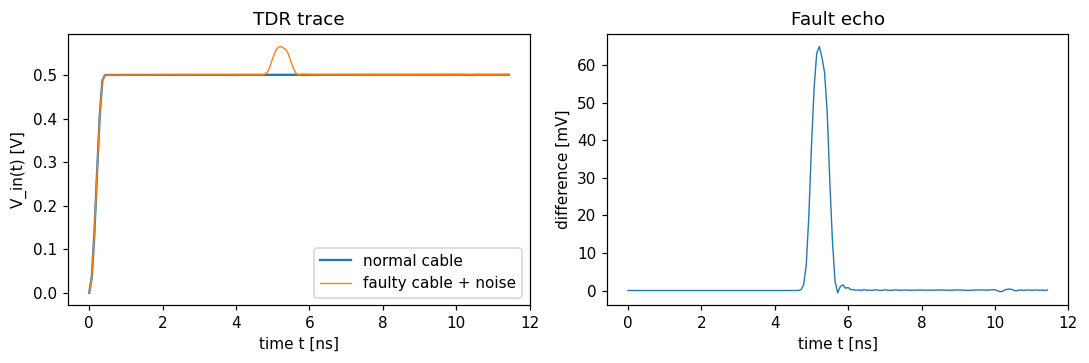

In [ ]:
_, v_nom = measured_trace(np.full(NX, R0), np.full(NX, C0), 0.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t*1e9, v_nom, label='normal cable'); ax[0].plot(t*1e9, v_meas, label='faulty cable + noise', lw=.9)
ax[0].set_xlabel('time t [ns]'); ax[0].set_ylabel('V_in(t) [V]'); ax[0].legend(); ax[0].set_title('TDR trace')
ax[1].plot(t*1e9, (v_meas - v_nom)*1e3, lw=.9)
ax[1].set_xlabel('time t [ns]'); ax[1].set_ylabel('difference [mV]'); ax[1].set_title('Fault echo')
plt.tight_layout(); plt.show()

### Figure 2 - reconstructed R(x) and C(x) against the truth

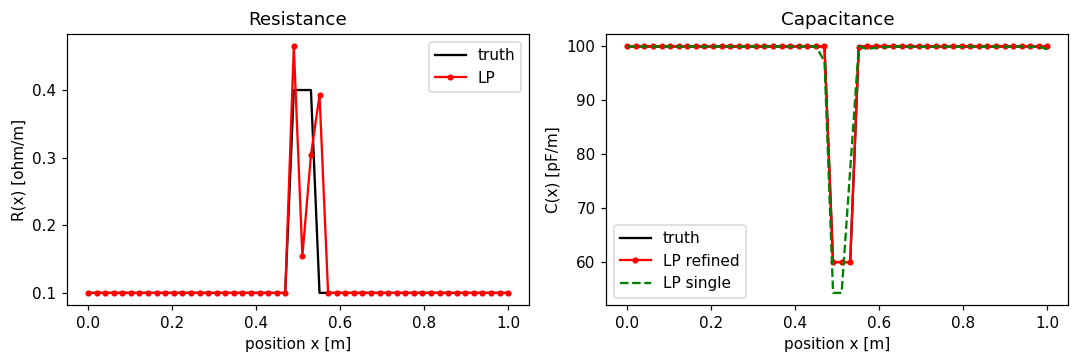

In [ ]:
x = np.arange(NX) * DX
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(x, R_true, 'k-', label='truth'); ax[0].plot(x, R_rec, 'r.-', label='LP')
ax[0].set_xlabel('position x [m]'); ax[0].set_ylabel('R(x) [ohm/m]'); ax[0].legend(); ax[0].set_title('Resistance')
ax[1].plot(x, C_true*1e12, 'k-', label='truth'); ax[1].plot(x, C_rec*1e12, 'r.-', label='LP refined')
ax[1].plot(x, C0*(1-d1)*1e12, 'g--', label='LP single')
ax[1].set_xlabel('position x [m]'); ax[1].set_ylabel('C(x) [pF/m]'); ax[1].legend(); ax[1].set_title('Capacitance')
plt.tight_layout(); plt.show()

### Figure 3 - residual (how well the answer explains the recording)

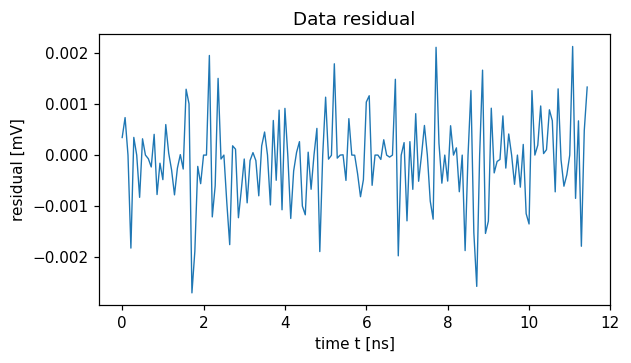

In [ ]:
_, v_fit = model_trace(r3, d3); _, v_nm = model_trace(np.zeros(NX), np.zeros(NX))
target = v_meas - ref + v_nm
plt.figure(figsize=(6, 3.2)); plt.plot(t*1e9, (target - v_fit)*1e3, lw=.9)
plt.xlabel('time t [ns]'); plt.ylabel('residual [mV]'); plt.title('Data residual'); plt.show()

## 6. Does noise move the answer? (goal: at most 1 cell)

In [ ]:
sigmas = [0.0, 1e-5, 1e-4, 1e-3]
base = fault_location(invert(measured_trace(R_true, C_true, 0.0)[1], 0, v_ref=ref, restrict_r=False)[1])
for sg in sigmas:
    locs = [fault_location(invert(measured_trace(R_true, C_true, sg, seed=k)[1], 0, v_ref=ref, restrict_r=False)[1]) for k in range(10)]
    print(f'noise {sg:.0e} V: largest shift = {np.abs(np.array(locs) - base).max():.2f} cells')
print()
print('R recovery versus noise (truth: nodes 24-26, factor 4):')
for sg in [0.0, 1e-6, 1e-5, 1e-4]:
    rr = invert(measured_trace(R_true, C_true, sg, seed=1)[1], 3, v_ref=ref)[0]
    print(f'  noise {sg:.0e} V -> R peak at node {int(rr.argmax())}, R/R0 = {1 + rr.max():.2f}')

noise 0e+00 V: largest shift = 0.00 cells
noise 1e-05 V: largest shift = 0.00 cells
noise 1e-04 V: largest shift = 0.00 cells
noise 1e-03 V: largest shift = 0.02 cells

R recovery versus noise (truth: nodes 24-26, factor 4):
  noise 0e+00 V -> R peak at node 24, R/R0 = 4.00
  noise 1e-06 V -> R peak at node 24, R/R0 = 4.64
  noise 1e-05 V -> R peak at node 27, R/R0 = 6.00
  noise 1e-04 V -> R peak at node 27, R/R0 = 6.00


## 7. Honest limitation
The capacitance dip is found accurately at every noise level tested. The **resistance spike is far weaker**: its echo is about 1e-4 V, roughly 650 times smaller than the capacitance echo. It is recovered inside the fault region only for noise of about 1 microvolt or less; with more noise the R value drifts (see the last printed table). We therefore (1) fit C first, (2) let R change only where the fitted C shows the fault.

**Bug fixed in this version:** the capacitance deficit was allowed to reach 0.95. Below about 0.49 of the nominal C the Courant number exceeds 1, the model blew up and the LP failed. The bound is now set from the CFL limit (about 0.457).